In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("creditcard.csv")

# Display dataset information
print("Dataset shape:", data.shape)
print(data.head())

# Check columns
print("Columns:", data.columns.tolist())

# Check missing values
print("Missing values:", data.isnull().sum().sum())

# Check class distribution
print(data["Class"].value_counts())

Dataset shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

    

In [3]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = data.drop("Class", axis=1)
y = data["Class"]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Keep only normal transactions (Class = 0)
X_normal = X_scaled[y == 0]

print("Scaled data shape:", X_scaled.shape)
print("Normal transaction shape:", X_normal.shape)

Scaled data shape: (284807, 30)
Normal transaction shape: (284315, 30)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)

Training data shape: (227452, 30)
Validation data shape: (56863, 30)


In [5]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Number of input features
input_dim = X_train.shape[1]

# Input layer
input_layer = Input(shape=(input_dim,))

# Encoder
encoder = Dense(32, activation="relu")(input_layer)
encoder = Dense(16, activation="relu")(encoder)
encoded = Dense(8, activation="relu")(encoder)

# Decoder
decoder = Dense(16, activation="relu")(encoded)
decoder = Dense(32, activation="relu")(decoder)
decoded = Dense(input_dim, activation="linear")(decoder)

# Autoencoder model
autoencoder = Model(input_layer, decoded)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,334 (13.02 KB)

 Trainable params: 3,334 (13.02 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [7]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val, X_val)
)

Epoch 1/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.6628 - mae: 0.5532 - val_loss: 0.5055 - val_mae: 0.4898
Epoch 2/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.4575 - mae: 0.4672 - val_loss: 0.4187 - val_mae: 0.4475
Epoch 3/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.3792 - mae: 0.4251 - val_loss: 0.3511 - val_mae: 0.4065
Epoch 4/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.3336 - mae: 0.3964 - val_loss: 0.3226 - val_mae: 0.3867
Epoch 5/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.3120 - mae: 0.3823 - val_loss: 0.3111 - val_mae: 0.3806
Epoch 6/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2978 - mae: 0.3724 - val_loss: 0.2981 - val_mae: 0.3730
Epoch 7/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2874 - mae: 0.3651 - val_loss: 0.2845 - val_mae: 0.3611
Epoch 8/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2787 - mae: 0.3586 - val_loss: 0.2774 - val_mae: 0.3555
Epoch 9/20
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - lo

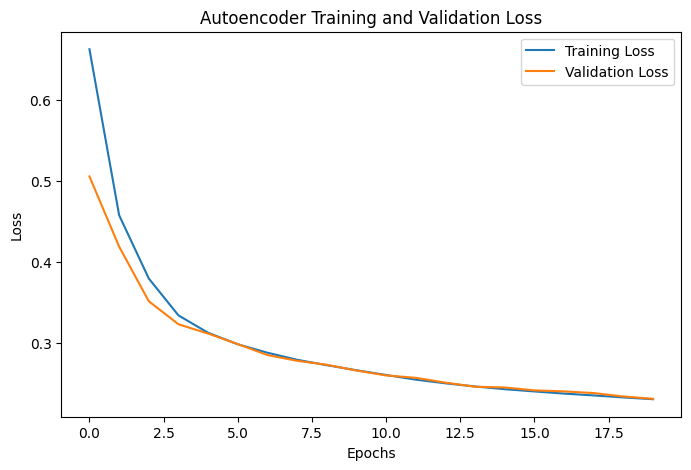

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.show()

In [9]:
# Reconstruct all transactions
X_pred = autoencoder.predict(X_scaled)

# Calculate mean squared reconstruction error
reconstruction_error = np.mean(
    np.square(X_scaled - X_pred),
    axis=1
)

print("Reconstruction error calculated.")

8901/8901 ━━━━━━━━━━━━━━━━━━━━ 7s 828us/step
Reconstruction error calculated.


In [10]:
# Reconstruction errors for normal training transactions
train_pred = autoencoder.predict(X_train)

train_error = np.mean(
    np.square(X_train - train_pred),
    axis=1
)

# Set threshold
threshold = np.percentile(train_error, 95)

print("Threshold:", threshold)

# Detect fraud
y_pred = (reconstruction_error > threshold).astype(int)

print("Fraud detection completed.")

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 6s 837us/step
Threshold: 0.6323611782384577
Fraud detection completed.


In [11]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y, y_pred))

print("\nClassification Report:")
print(classification_report(y, y_pred))

Confusion Matrix:
[[270053  14262]
 [    75    417]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    284315
           1       0.03      0.85      0.05       492

    accuracy                           0.95    284807
   macro avg       0.51      0.90      0.51    284807
weighted avg       1.00      0.95      0.97    284807



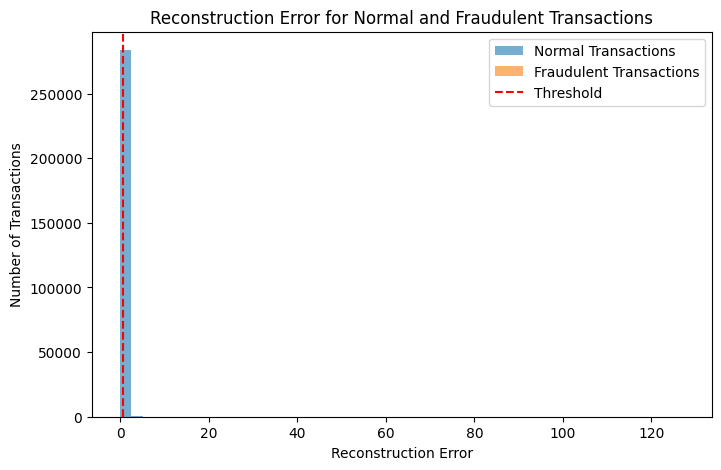

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(
    reconstruction_error[y == 0],
    bins=50,
    alpha=0.6,
    label="Normal Transactions"
)

plt.hist(
    reconstruction_error[y == 1],
    bins=50,
    alpha=0.6,
    label="Fraudulent Transactions"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="dashed",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.title("Reconstruction Error for Normal and Fraudulent Transactions")
plt.legend()
plt.show()